In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df = pd.read_csv('/content/drive/MyDrive/Rayong2_Surface_Water_Quality_2018-2024.csv')

In [ ]:
df.head()

,แม่น้ำ,ประเภทแหล่งน้ำ,Station,ปี,DO(mg/l),BOD(mg/l),TCB(MPN/100ml),FCB(MPN/100ml),NO3-N(mg/l),NH3-N(mg/l),WQI
0,แม่น้ำระยอง,4,RY01,2561,6.86,1.4,"2,200",940,0.05,0.14,79.19
1,แม่น้ำระยอง,4,RY02,2561,5.17,1.4,"1,100",110,0.07,0.06,84.68
2,แม่น้ำระยอง,4,RY03,2561,0.95,2.2,"160,000","13,000",0.61,1.64,29.34
3,แม่น้ำระยอง,4,RY04,2561,3.32,1.6,"3,300",260,1.43,0.17,64.21
4,แม่น้ำระยอง,3,RY05,2561,2.91,1.6,"24,000","16,000",0.62,0.14,52.79


In [ ]:
df.shape

(447, 11)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 447 entries, 0 to 446
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   แม่น้ำ          447 non-null    object 
 1   ประเภทแหล่งน้ำ  447 non-null    int64  
 2   Station         447 non-null    object 
 3   ปี              447 non-null    int64  
 4   DO(mg/l)        447 non-null    float64
 5   BOD(mg/l)       447 non-null    float64
 6   TCB(MPN/100ml)  447 non-null    object 
 7   FCB(MPN/100ml)  447 non-null    object 
 8   NO3-N(mg/l)     447 non-null    object 
 9   NH3-N(mg/l)     447 non-null    object 
 10  WQI             447 non-null    float64
dtypes: float64(3), int64(2), object(6)
memory usage: 38.5+ KB


In [ ]:
df.describe()

,ประเภทแหล่งน้ำ,ปี,DO(mg/l),BOD(mg/l),WQI
count,447.000000,447.000000,447.000000,447.000000,447.000000
mean,3.129754,2564.248322,4.671521,1.649441,61.269821
std,0.596090,2.125774,1.514213,1.231552,11.904114
min,2.000000,2561.000000,0.470000,0.200000,26.690000
25%,3.000000,2562.000000,3.730000,1.000000,56.035000
50%,3.000000,2564.000000,4.800000,1.400000,60.220000
75%,3.500000,2566.000000,5.760000,1.800000,68.110000
max,4.000000,2567.000000,9.490000,16.100000,93.810000


In [ ]:
df.isnull().sum()

,0
แม่น้ำ,0
ประเภทแหล่งน้ำ,0
Station,0
ปี,0
DO(mg/l),0
BOD(mg/l),0
TCB(MPN/100ml),0
FCB(MPN/100ml),0
NO3-N(mg/l),0
NH3-N(mg/l),0


In [ ]:
df.columns

Index(['แม่น้ำ', 'ประเภทแหล่งน้ำ', 'Station', 'ปี', 'DO(mg/l)', 'BOD(mg/l)',
       'TCB(MPN/100ml)', 'FCB(MPN/100ml)', 'NO3-N(mg/l)', 'NH3-N(mg/l)',
       'WQI'],
      dtype='object')

In [ ]:
df.columns = [
    "River",
    "Water_Type",
    "Station",
    "Year",
    "DO",
    "BOD",
    "TCB",
    "FCB",
    "NO3_N",
    "NH3_N",
    "WQI"
]

df.head()

,River,Water_Type,Station,Year,DO,BOD,TCB,FCB,NO3_N,NH3_N,WQI
0,แม่น้ำระยอง,4,RY01,2561,6.86,1.4,"2,200",940,0.05,0.14,79.19
1,แม่น้ำระยอง,4,RY02,2561,5.17,1.4,"1,100",110,0.07,0.06,84.68
2,แม่น้ำระยอง,4,RY03,2561,0.95,2.2,"160,000","13,000",0.61,1.64,29.34
3,แม่น้ำระยอง,4,RY04,2561,3.32,1.6,"3,300",260,1.43,0.17,64.21
4,แม่น้ำระยอง,3,RY05,2561,2.91,1.6,"24,000","16,000",0.62,0.14,52.79


In [ ]:
df["Year"] = df["Year"] - 543

df.head()

,River,Water_Type,Station,Year,DO,BOD,TCB,FCB,NO3_N,NH3_N,WQI
0,แม่น้ำระยอง,4,RY01,2018,6.86,1.4,"2,200",940,0.05,0.14,79.19
1,แม่น้ำระยอง,4,RY02,2018,5.17,1.4,"1,100",110,0.07,0.06,84.68
2,แม่น้ำระยอง,4,RY03,2018,0.95,2.2,"160,000","13,000",0.61,1.64,29.34
3,แม่น้ำระยอง,4,RY04,2018,3.32,1.6,"3,300",260,1.43,0.17,64.21
4,แม่น้ำระยอง,3,RY05,2018,2.91,1.6,"24,000","16,000",0.62,0.14,52.79


In [ ]:
print("Total records:", len(df))

print("Number of rivers:", df["River"].nunique())

print("Number of stations:", df["Station"].nunique())

print("\nRecords by year:")

print(df["Year"].value_counts().sort_index())

Total records: 447
Number of rivers: 3
Number of stations: 27

Records by year:
Year
2018     60
2019     60
2020     60
2021     60
2022     45
2023     60
2024    102
Name: count, dtype: int64


Data Cleaning

In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
# Check duplicates excluding the year column

subset_columns = [
    col for col in df.columns
    if col != "Year"
]

duplicate_records = df[
    df.duplicated(
        subset=subset_columns,
        keep=False
    )
]

duplicate_records.sort_values(["Station", "Year"])

,River,Water_Type,Station,Year,DO,BOD,TCB,FCB,NO3_N,NH3_N,WQI
36,แม่น้ำประแสร์,3,PE01,2018,6.34,1.1,"9,200","3,500",0.23,0.28,70.84
321,แม่น้ำประแสร์,3,PE01,2023,6.34,1.1,"9,200","3,500",0.23,0.28,70.84
37,แม่น้ำประแสร์,3,PE02,2018,6.17,1.4,"3,500",790,0.23,0.64,57.16
322,แม่น้ำประแสร์,3,PE02,2023,6.17,1.4,"3,500",790,0.23,0.64,57.16
38,แม่น้ำประแสร์,3,PE03,2018,6.19,0.9,"3,500",330,0.29,0.25,69.12
323,แม่น้ำประแสร์,3,PE03,2023,6.19,0.9,"3,500",330,0.29,0.25,69.12
39,แม่น้ำประแสร์,3,PE04,2018,6.37,0.8,"9,200",78,0.31,0.45,67.74
324,แม่น้ำประแสร์,3,PE04,2023,6.37,0.8,"9,200",78,0.31,0.45,67.74
40,แม่น้ำประแสร์,3,PE05,2018,6.95,1.1,"5,400",330,0.23,0.29,68.11
325,แม่น้ำประแสร์,3,PE05,2023,6.95,1.1,"5,400",330,0.23,0.29,68.11


In [ ]:
duplicate_records["Year"].value_counts().sort_index()

,count
Year,
2018,15
2023,15


In [ ]:
df = df.sort_values("Year", kind="stable")

df = df.drop_duplicates(
    subset=subset_columns,
    keep="first"
)

df = df.reset_index(drop=True)

print("Remaining records:", len(df))

Remaining records: 432


In [ ]:
duplicate_records["Year"].value_counts().sort_index()

,count
Year,
2018,15
2023,15


In [ ]:
parameters = [
    "DO",
    "BOD",
    "TCB",
    "FCB",
    "NO3_N",
    "NH3_N"
]

for col in parameters:

    values = df[col].astype(str)
    values = values.str.replace(",", "", regex=False)

    numeric = pd.to_numeric(
        values,
        errors="coerce"
    )

    print(col, ":", values[numeric.isna()].unique())

DO : []
BOD : []
TCB : ['<18' '>160000']
FCB : ['<18']
NO3_N : ['<0.02' 'q2']
NH3_N : ['<0.03']


In [ ]:
for col in parameters:

    values = df[col].astype(str).str.strip()

    values = values.str.replace(
        ",", "", regex=False
    )

    below_limit = values.str.startswith("<")

    numeric_values = pd.to_numeric(
        values.str.replace(
            r"^[<>]\s*", "", regex=True
        ),
        errors="coerce"
    ).astype(float)

    numeric_values.loc[below_limit] = (
        numeric_values.loc[below_limit] / 2
    )

    df[col] = numeric_values

In [ ]:
df.isnull().sum()

,0
River,0
Water_Type,0
Station,0
Year,0
DO,0
BOD,0
TCB,0
FCB,0
NO3_N,1
NH3_N,0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 432 entries, 0 to 431
Data columns (total 11 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   River       432 non-null    object 
 1   Water_Type  432 non-null    int64  
 2   Station     432 non-null    object 
 3   Year        432 non-null    int64  
 4   DO          432 non-null    float64
 5   BOD         432 non-null    float64
 6   TCB         432 non-null    float64
 7   FCB         432 non-null    float64
 8   NO3_N       431 non-null    float64
 9   NH3_N       432 non-null    float64
 10  WQI         432 non-null    float64
dtypes: float64(7), int64(2), object(2)
memory usage: 37.3+ KB


In [ ]:
df.describe()

,Water_Type,Year,DO,BOD,TCB,FCB,NO3_N,NH3_N,WQI
count,432.000000,432.000000,432.000000,432.000000,432.0000,432.000000,431.000000,432.000000,432.000000
mean,3.129630,2021.187500,4.650000,1.654630,19460.3750,3665.921296,0.432807,0.752951,61.222917
std,0.595304,2.136748,1.514232,1.249158,39579.5893,14776.396436,0.372804,1.403993,12.063148
min,2.000000,2018.000000,0.470000,0.200000,9.0000,9.000000,0.010000,0.015000,26.690000
25%,3.000000,2019.000000,3.735000,1.000000,790.0000,130.000000,0.115000,0.280000,55.885000
50%,3.000000,2021.000000,4.780000,1.400000,3500.0000,330.000000,0.390000,0.560000,60.220000
75%,3.250000,2023.000000,5.735000,1.800000,16000.0000,1700.000000,0.635000,0.910000,68.142500
max,4.000000,2024.000000,9.490000,16.100000,160000.0000,160000.000000,3.150000,26.700000,93.810000


In [ ]:
# Scenario A: Full parameters

features_full = [
    "DO",
    "BOD",
    "TCB",
    "FCB",
    "NO3_N",
    "NH3_N"
]

# Scenario B: Reduced parameters

features_reduced = [
    "DO",
    "NO3_N",
    "NH3_N"
]

# Target variable

target = "WQI"

Train-Test Split

In [ ]:
train_df = df[df["Year"] <= 2023].copy()

test_df = df[df["Year"] == 2024].copy()

In [ ]:
# Reduced-parameter scenario

X_train = train_df[features_reduced]
y_train = train_df[target]

X_test = test_df[features_reduced]
y_test = test_df[target]

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)

Training set: (330, 3)
Testing set: (102, 3)


Descriptive Stat

In [ ]:
train_df[features_full + [target]].describe()

,DO,BOD,TCB,FCB,NO3_N,NH3_N,WQI
count,330.000000,330.000000,330.000000,330.000000,329.000000,330.000000,330.000000
mean,4.723545,1.597879,20418.030303,4291.357576,0.417173,0.647136,62.093242
std,1.496952,1.234741,41127.680399,16756.362529,0.356451,0.566236,12.408189
min,0.470000,0.200000,9.000000,9.000000,0.010000,0.015000,26.690000
25%,3.750000,1.000000,940.000000,130.000000,0.100000,0.270000,56.220000
50%,4.930000,1.300000,3500.000000,330.000000,0.360000,0.515000,60.790000
75%,5.785000,1.800000,16000.000000,2100.000000,0.640000,0.850000,69.632500
max,9.050000,16.100000,160000.000000,160000.000000,1.610000,3.110000,93.810000


Distribution of WQI

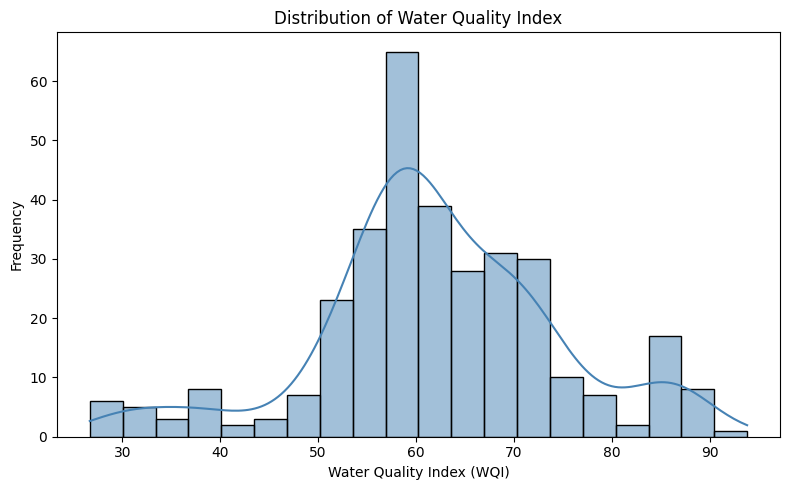

In [ ]:
plt.figure(figsize=(8, 5))

sns.histplot(
    train_df["WQI"],
    bins=20,
    kde=True,
    color="steelblue"
)

plt.title("Distribution of Water Quality Index")
plt.xlabel("Water Quality Index (WQI)")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

Outlier Detection

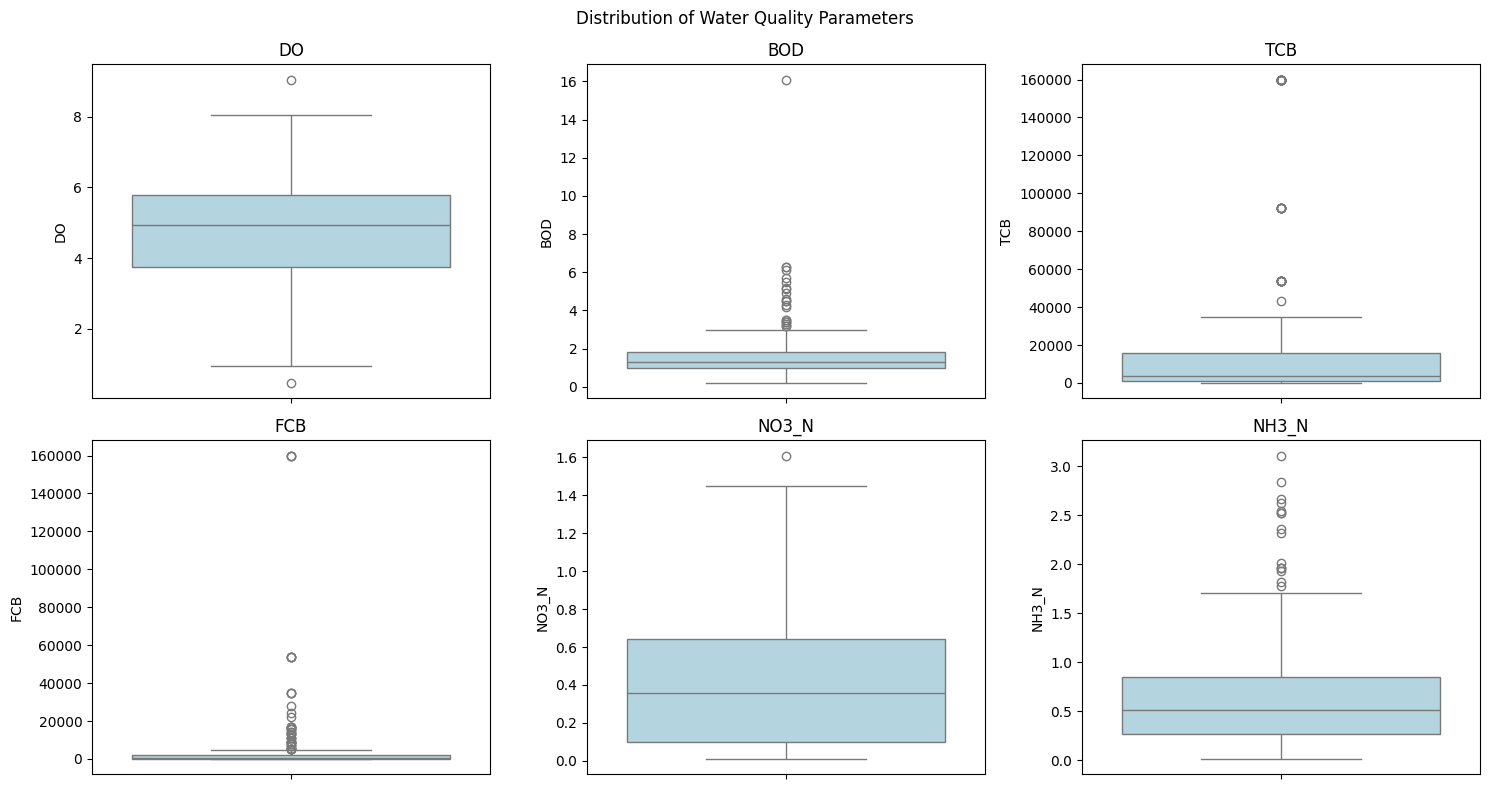

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for i, col in enumerate(features_full):

    sns.boxplot(
        y=train_df[col],
        ax=axes.flat[i],
        color="lightblue"
    )

    axes.flat[i].set_title(col)

plt.suptitle("Distribution of Water Quality Parameters")

plt.tight_layout()
plt.show()

Heatmap

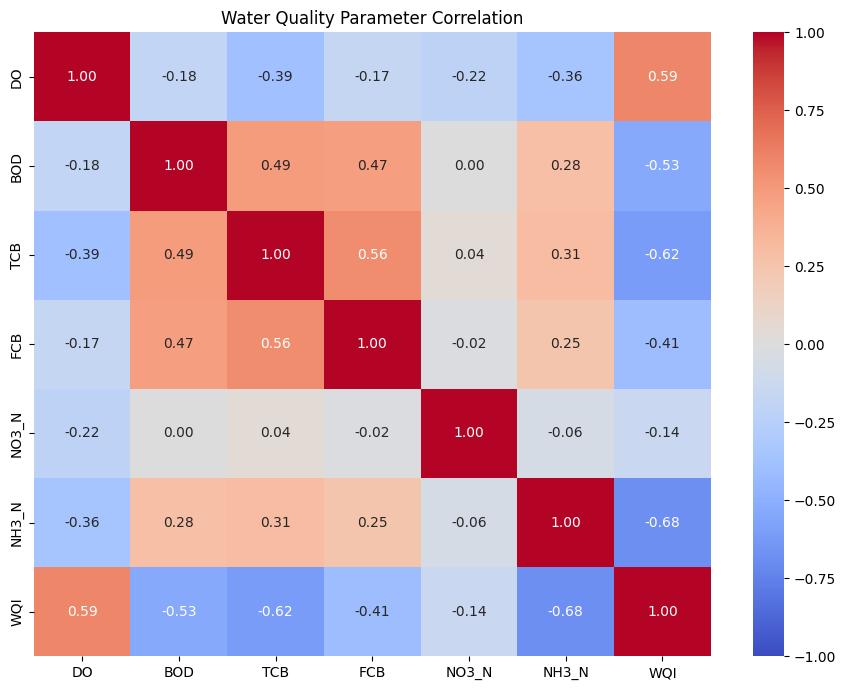

In [ ]:
correlation = train_df[
    features_full + [target]
].corr()

plt.figure(figsize=(9, 7))

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.title("Water Quality Parameter Correlation")

plt.tight_layout()
plt.show()

Correlation

In [ ]:
correlation["WQI"].sort_values(
    ascending=False
)

,WQI
WQI,1.000000
DO,0.589185
NO3_N,-0.140769
FCB,-0.413446
BOD,-0.533363
TCB,-0.616324
NH3_N,-0.682775


Scatter Plot

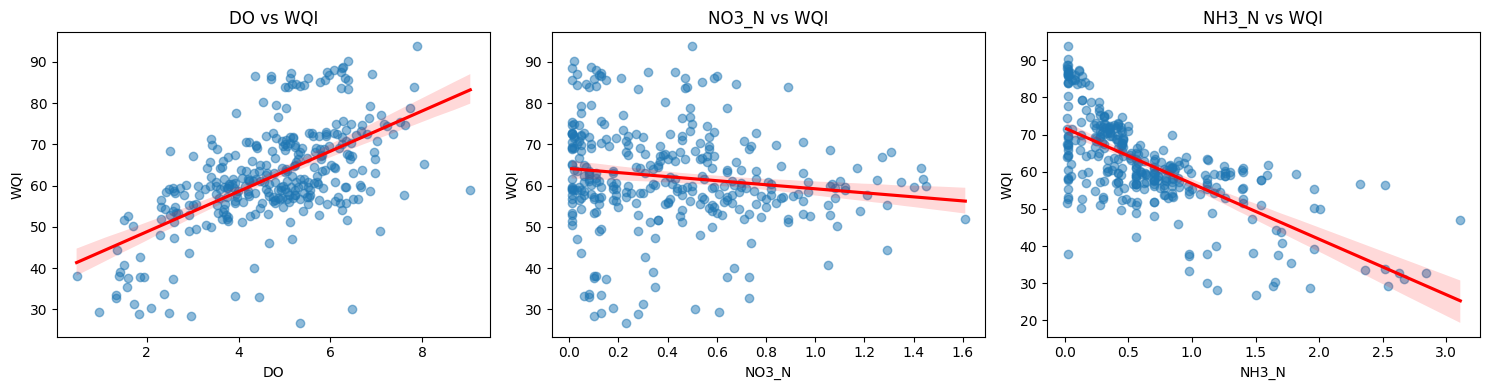

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for i, col in enumerate(features_reduced):

    sns.regplot(
        data=train_df,
        x=col,
        y="WQI",
        ax=axes[i],
        scatter_kws={"alpha": 0.5},
        line_kws={"color": "red"}
    )

    axes[i].set_title(f"{col} vs WQI")

plt.tight_layout()
plt.show()

Multiple Linear Regression

In [ ]:
from sklearn.linear_model import LinearRegression

from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

from sklearn.dummy import DummyRegressor

from sklearn.model_selection import GroupKFold
from sklearn.model_selection import cross_validate

from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)

In [ ]:
mlr_pipeline = Pipeline([

    ("imputer", SimpleImputer(strategy="median")),

    ("scaler", StandardScaler()),

    ("regression", LinearRegression())

])

In [ ]:
cv = GroupKFold(n_splits=5)

groups = train_df["Year"]

scoring = {
    "R2": "r2",
    "MAE": "neg_mean_absolute_error",
    "RMSE": "neg_root_mean_squared_error"
}

In [ ]:
models = {

    "Mean Baseline": DummyRegressor(
        strategy="mean"
    ),

    "Multiple Linear Regression": mlr_pipeline

}

In [ ]:
results = []

for name, model in models.items():

    scores = cross_validate(
        model,
        X_train,
        y_train,
        groups=groups,
        cv=cv,
        scoring=scoring
    )

    results.append({

        "Model": name,

        "R2": scores["test_R2"].mean(),

        "MAE": -scores["test_MAE"].mean(),

        "RMSE": -scores["test_RMSE"].mean()

    })

results_df = pd.DataFrame(results)

results_df.round(4)

,Model,R2,MAE,RMSE
0,Mean Baseline,-0.1237,9.5567,12.6303
1,Multiple Linear Regression,0.5416,6.2882,8.0598


Regularized Regression

In [ ]:
from sklearn.linear_model import Ridge, Lasso
from sklearn.model_selection import GridSearchCV

In [ ]:
# Ridge Regression

ridge_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("regression", Ridge())
])

In [ ]:
# Lasso Regression

lasso_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("regression", Lasso(max_iter=10000))
])

Esemble Learning

In [ ]:
from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor
)

from xgboost import XGBRegressor

In [ ]:
# Random Forest Regression

rf_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),

    ("regression", RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=1
    ))
])

In [ ]:
# Gradient Boosting Regression

gb_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),

    ("regression", GradientBoostingRegressor(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    ))
])

In [ ]:
# XGBoost Regression

xgb_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),

    ("regression", XGBRegressor(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42,
        n_jobs=1
    ))
])

Comparision

In [ ]:
models = {
    "Mean Baseline": DummyRegressor(strategy="mean"),
    "Multiple Linear Regression": mlr_pipeline,
    "Ridge Regression": ridge_pipeline,
    "Lasso Regression": lasso_pipeline,
    "Random Forest": rf_pipeline,
    "Gradient Boosting": gb_pipeline,
    "XGBoost": xgb_pipeline
}

In [ ]:
results = []

for name, model in models.items():

    scores = cross_validate(
        model,
        X_train,
        y_train,
        groups=groups,
        cv=cv,
        scoring=scoring
    )

    results.append({
        "Model": name,
        "R2": scores["test_R2"].mean(),
        "MAE": -scores["test_MAE"].mean(),
        "RMSE": -scores["test_RMSE"].mean()
    })

results_df = pd.DataFrame(results)

results_df.round(4)

,Model,R2,MAE,RMSE
0,Mean Baseline,-0.1237,9.5567,12.6303
1,Multiple Linear Regression,0.5416,6.2882,8.0598
2,Ridge Regression,0.5421,6.2845,8.0570
3,Lasso Regression,0.5366,6.2817,8.1192
4,Random Forest,0.4882,6.2810,8.5096
5,Gradient Boosting,0.5133,6.1668,8.2840
6,XGBoost,0.5324,6.0188,8.1322


Hyperparameter Tuning

In [ ]:
param_grids = {

    "Ridge Regression": {
        "regression__alpha": [
            0.001, 0.01, 0.1, 1, 10, 100
        ]
    },

    "Lasso Regression": {
        "regression__alpha": [
            0.001, 0.01, 0.1, 1, 10, 100
        ]
    },

    "Random Forest": {
        "regression__n_estimators": [100, 200],
        "regression__max_depth": [3, 5, 10],
        "regression__min_samples_leaf": [1, 2, 5]
    },

    "Gradient Boosting": {
        "regression__n_estimators": [100, 200],
        "regression__learning_rate": [0.05, 0.1],
        "regression__max_depth": [2, 3, 5]
    },

    "XGBoost": {
        "regression__n_estimators": [100, 200],
        "regression__learning_rate": [0.05, 0.1],
        "regression__max_depth": [2, 3, 5]
    }
}

In [ ]:
from sklearn.base import clone

tuned_models = {}
tuned_results = []

for name, model in models.items():

    if name in param_grids:

        grid = GridSearchCV(
            model,
            param_grids[name],
            cv=cv,
            scoring=scoring,
            refit="R2",
            n_jobs=2
        )

        grid.fit(
            X_train,
            y_train,
            groups=groups
        )

        tuned_models[name] = grid.best_estimator_

        idx = grid.best_index_

        r2 = grid.cv_results_["mean_test_R2"][idx]

        mae = -grid.cv_results_["mean_test_MAE"][idx]

        rmse = -grid.cv_results_["mean_test_RMSE"][idx]

        print(name)
        print("Best Parameters:", grid.best_params_)
        print("Best CV R2:", round(r2, 4))
        print("-" * 40)

    else:

        scores = cross_validate(
            model,
            X_train,
            y_train,
            groups=groups,
            cv=cv,
            scoring=scoring
        )

        tuned_models[name] = clone(model).fit(
            X_train, y_train
        )

        r2 = scores["test_R2"].mean()

        mae = -scores["test_MAE"].mean()

        rmse = -scores["test_RMSE"].mean()

    tuned_results.append({
        "Model": name,
        "R2": r2,
        "MAE": mae,
        "RMSE": rmse
    })

Ridge Regression
Best Parameters: {'regression__alpha': 10}
Best CV R2: 0.5453
----------------------------------------
Lasso Regression
Best Parameters: {'regression__alpha': 0.1}
Best CV R2: 0.5424
----------------------------------------
Random Forest
Best Parameters: {'regression__max_depth': 3, 'regression__min_samples_leaf': 1, 'regression__n_estimators': 100}
Best CV R2: 0.5705
----------------------------------------
Gradient Boosting
Best Parameters: {'regression__learning_rate': 0.05, 'regression__max_depth': 2, 'regression__n_estimators': 100}
Best CV R2: 0.5766
----------------------------------------
XGBoost
Best Parameters: {'regression__learning_rate': 0.05, 'regression__max_depth': 2, 'regression__n_estimators': 100}
Best CV R2: 0.5811
----------------------------------------


In [ ]:
tuned_results_df = pd.DataFrame(tuned_results)

tuned_results_df = tuned_results_df.sort_values(
    by="R2",
    ascending=False
)

tuned_results_df.round(4)

,Model,R2,MAE,RMSE
6,XGBoost,0.5811,5.8017,7.6949
5,Gradient Boosting,0.5766,5.8434,7.7396
4,Random Forest,0.5705,5.8953,7.7725
2,Ridge Regression,0.5453,6.2604,8.0379
3,Lasso Regression,0.5424,6.2813,8.0547
1,Multiple Linear Regression,0.5416,6.2882,8.0598
0,Mean Baseline,-0.1237,9.5567,12.6303


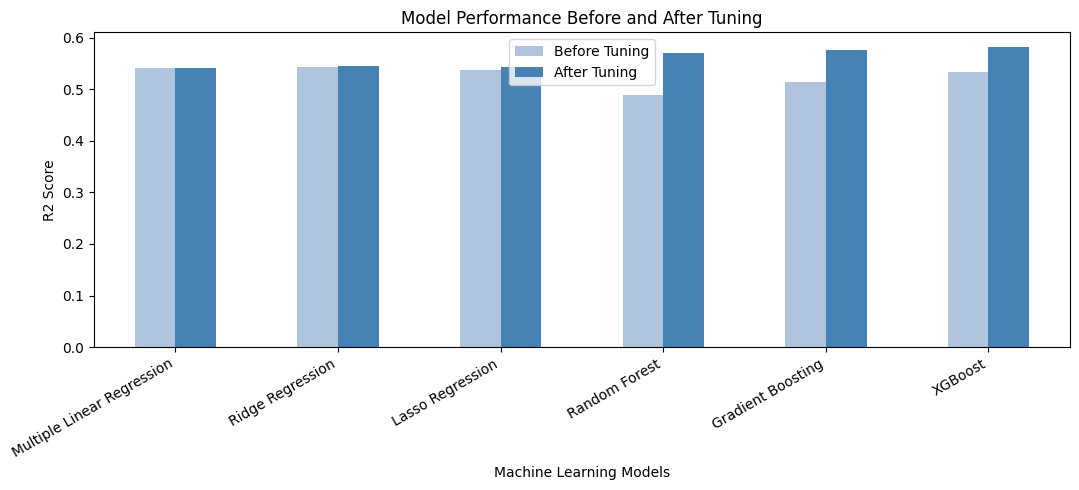

In [ ]:
comparison = results_df.merge(
    tuned_results_df,
    on="Model",
    suffixes=("_Before", "_After")
)

comparison = comparison[
    comparison["Model"] != "Mean Baseline"
]

comparison.set_index("Model")[
    ["R2_Before", "R2_After"]
].plot(
    kind="bar",
    figsize=(11, 5),
    color=["lightsteelblue", "steelblue"]
)

plt.title("Model Performance Before and After Tuning")
plt.ylabel("R2 Score")
plt.xlabel("Machine Learning Models")
plt.xticks(rotation=30, ha="right")
plt.legend(["Before Tuning", "After Tuning"])
plt.tight_layout()
plt.show()

Select the best model

In [ ]:
best_name = tuned_results_df[
    tuned_results_df["Model"] != "Mean Baseline"
].iloc[0]["Model"]

best_model = tuned_models[best_name]

print("Best Model:", best_name)

print("Best Hyperparameters:")

print(best_model.named_steps["regression"])

Best Model: XGBoost
Best Hyperparameters:
XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device=None, early_stopping_rounds=None,
             enable_categorical=True, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=0.05, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=2,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=100,
             n_jobs=1, num_parallel_tree=None, ...)


Final Model Evaluation

In [ ]:
test_results = []

for name, model in tuned_models.items():

    y_pred = model.predict(X_test)

    r2 = r2_score(y_test, y_pred)

    mae = mean_absolute_error(y_test, y_pred)

    mse = mean_squared_error(y_test, y_pred)

    rmse = np.sqrt(mse)

    test_results.append({
        "Model": name,
        "R2": r2,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse
    })

test_results_df = pd.DataFrame(test_results)

test_results_df.sort_values(
    "R2", ascending=False
).round(4)

,Model,R2,MAE,MSE,RMSE
6,XGBoost,0.6854,4.2617,33.9466,5.8264
5,Gradient Boosting,0.6613,4.4890,36.5425,6.0450
4,Random Forest,0.6545,4.5260,37.2811,6.1058
0,Mean Baseline,-0.1259,7.9383,121.4928,11.0224
2,Ridge Regression,-7.8059,8.3983,950.2030,30.8254
3,Lasso Regression,-8.0533,8.4657,976.9056,31.2555
1,Multiple Linear Regression,-8.2943,8.5384,1002.9057,31.6687


Actual VS Predicted WQI

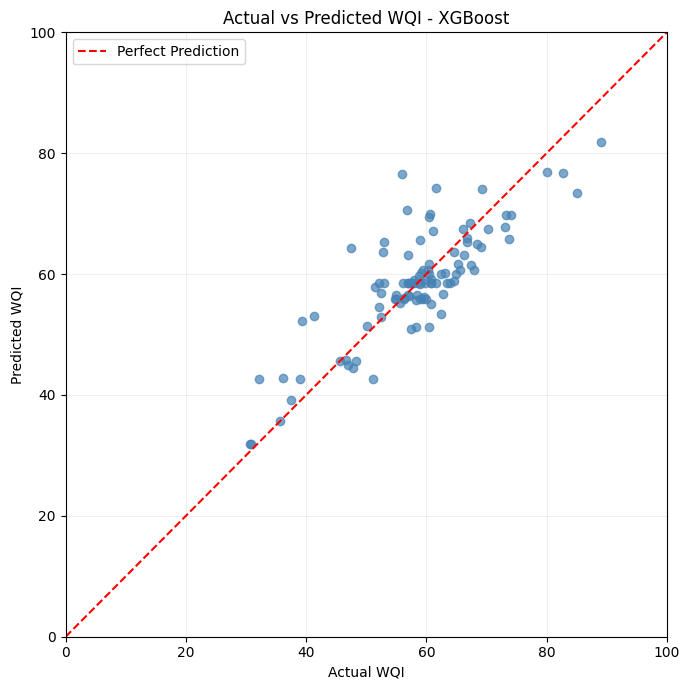

In [ ]:
y_pred_best = best_model.predict(X_test)

plt.figure(figsize=(7, 7))

plt.scatter(
    y_test,
    y_pred_best,
    alpha=0.7,
    color="steelblue"
)

plt.plot(
    [0, 100],
    [0, 100],
    "r--",
    label="Perfect Prediction"
)

plt.xlabel("Actual WQI")
plt.ylabel("Predicted WQI")
plt.title(f"Actual vs Predicted WQI - {best_name}")

plt.xlim(0, 100)
plt.ylim(0, 100)

plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

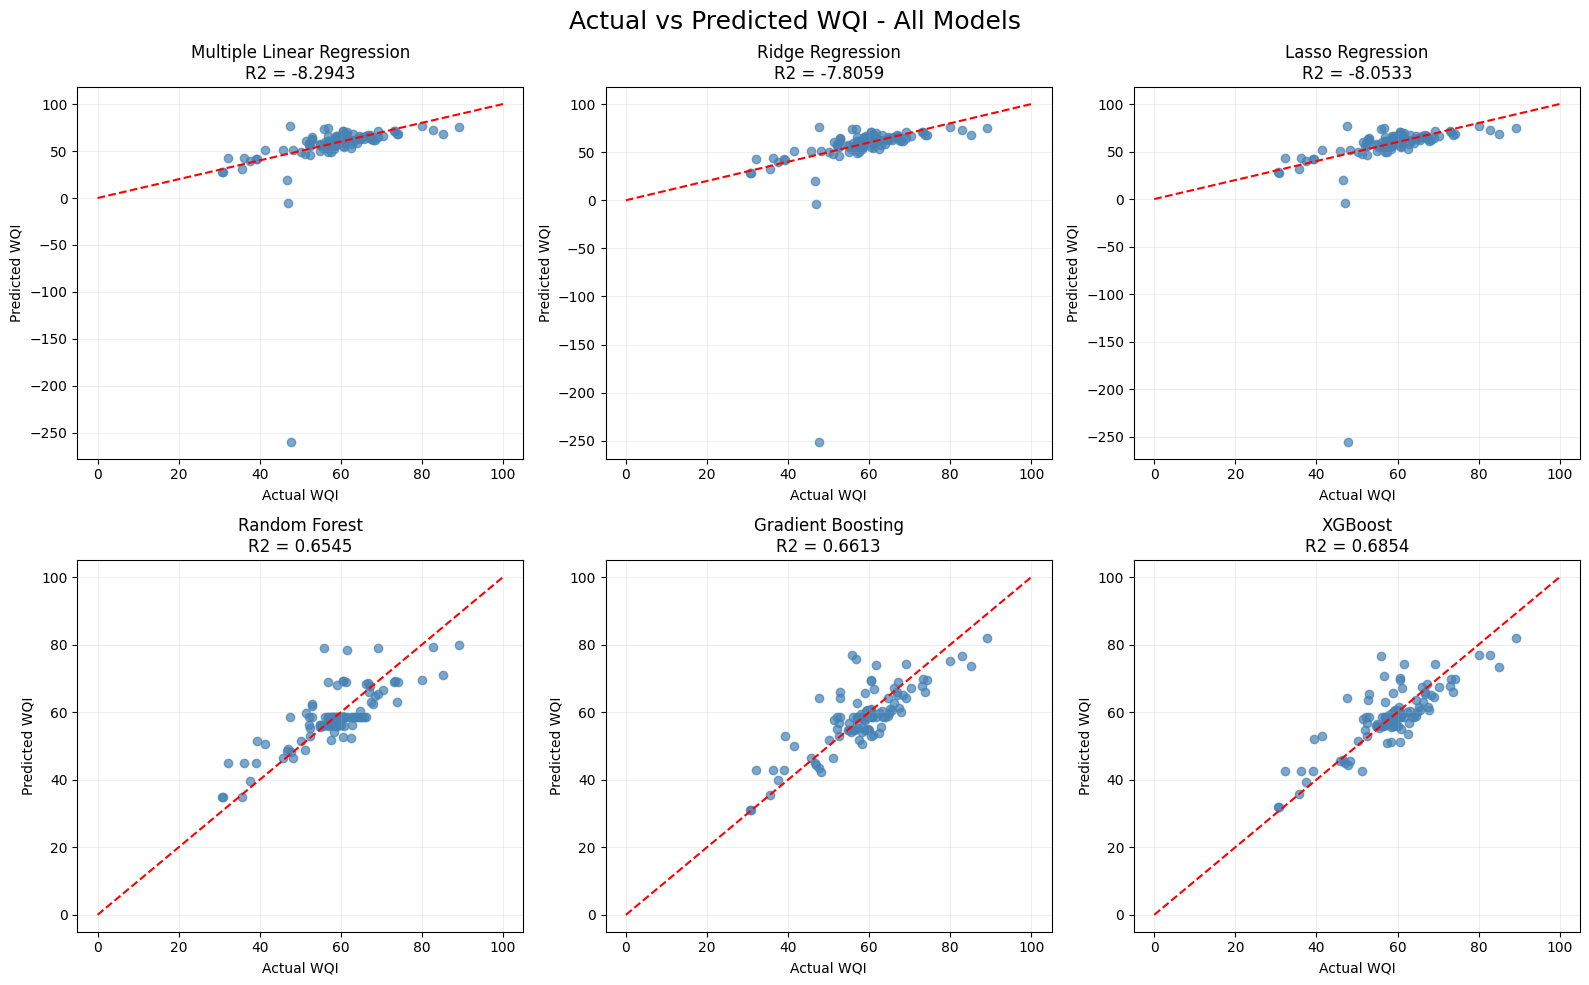

In [ ]:
fig, axes = plt.subplots(
    2, 3, figsize=(16, 10)
)

model_names = [
    "Multiple Linear Regression",
    "Ridge Regression",
    "Lasso Regression",
    "Random Forest",
    "Gradient Boosting",
    "XGBoost"
]

for i, name in enumerate(model_names):

    model = tuned_models[name]

    y_pred = model.predict(X_test)

    r2 = r2_score(y_test, y_pred)

    ax = axes.flat[i]

    ax.scatter(
        y_test,
        y_pred,
        color="steelblue",
        alpha=0.7
    )

    ax.plot(
        [0, 100],
        [0, 100],
        "r--"
    )

    ax.set_title(
        f"{name}\nR2 = {r2:.4f}"
    )

    ax.set_xlabel("Actual WQI")
    ax.set_ylabel("Predicted WQI")
    ax.grid(alpha=0.2)

plt.suptitle(
    "Actual vs Predicted WQI - All Models",
    fontsize=18
)

plt.tight_layout()
plt.show()

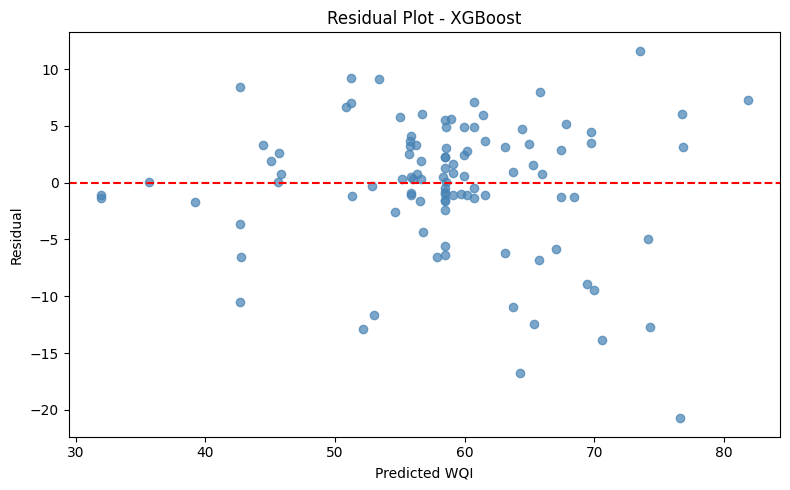

In [ ]:
residuals = y_test - y_pred_best

plt.figure(figsize=(8, 5))

plt.scatter(
    y_pred_best,
    residuals,
    alpha=0.7,
    color="steelblue"
)

plt.axhline(0, color="red", linestyle="--")

plt.xlabel("Predicted WQI")
plt.ylabel("Residual")
plt.title(f"Residual Plot - {best_name}")

plt.tight_layout()
plt.show()

In [ ]:
X_train_full = train_df[features_full]

X_test_full = test_df[features_full]

full_model = clone(best_model)

full_model.fit(
    X_train_full,
    y_train
)

y_pred_full = full_model.predict(X_test_full)

In [ ]:
scenario_results = pd.DataFrame([

    {
        "Scenario": "Full Parameters",
        "Features": 6,
        "R2": r2_score(y_test, y_pred_full),
        "MAE": mean_absolute_error(
            y_test, y_pred_full
        ),
        "RMSE": np.sqrt(
            mean_squared_error(y_test, y_pred_full)
        )
    },

    {
        "Scenario": "Reduced Parameters",
        "Features": 3,
        "R2": r2_score(y_test, y_pred_best),
        "MAE": mean_absolute_error(
            y_test, y_pred_best
        ),
        "RMSE": np.sqrt(
            mean_squared_error(y_test, y_pred_best)
        )
    }

])

scenario_results.round(4)

,Scenario,Features,R2,MAE,RMSE
0,Full Parameters,6,0.8422,3.1332,4.1259
1,Reduced Parameters,3,0.6854,4.2617,5.8264


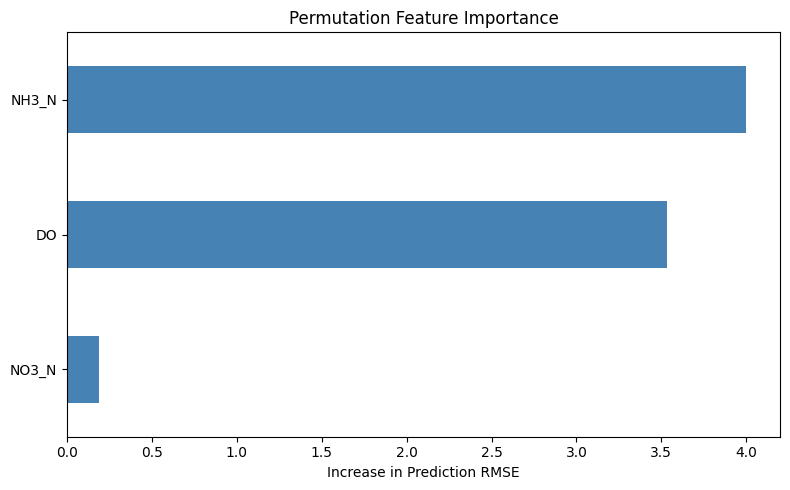

In [ ]:
from sklearn.inspection import permutation_importance

result = permutation_importance(
    best_model,
    X_test,
    y_test,
    scoring="neg_root_mean_squared_error",
    n_repeats=10,
    random_state=42
)

importance = pd.Series(
    result.importances_mean,
    index=X_test.columns
).sort_values()

importance.plot(
    kind="barh",
    figsize=(8, 5),
    color="steelblue"
)

plt.title("Permutation Feature Importance")
plt.xlabel("Increase in Prediction RMSE")
plt.tight_layout()
plt.show()

In [ ]:
import shap

tree_model = best_model.named_steps["regression"]

X_test_processed = pd.DataFrame(
    best_model.named_steps["imputer"].transform(X_test),
    columns=features_reduced,
    index=X_test.index
)

explainer = shap.TreeExplainer(tree_model)

shap_values = explainer(X_test_processed)

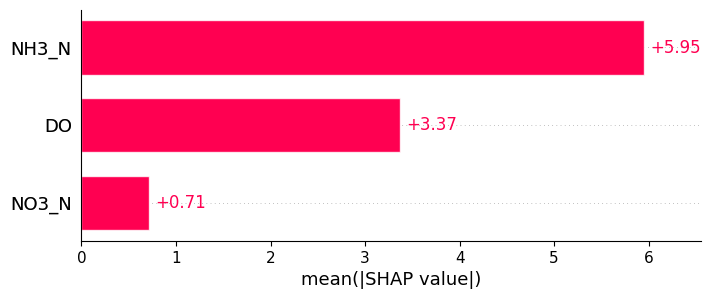

In [ ]:
shap.plots.bar(shap_values)

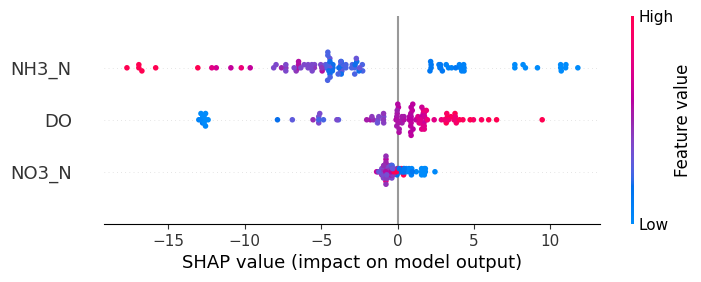

In [ ]:
shap.plots.beeswarm(shap_values)

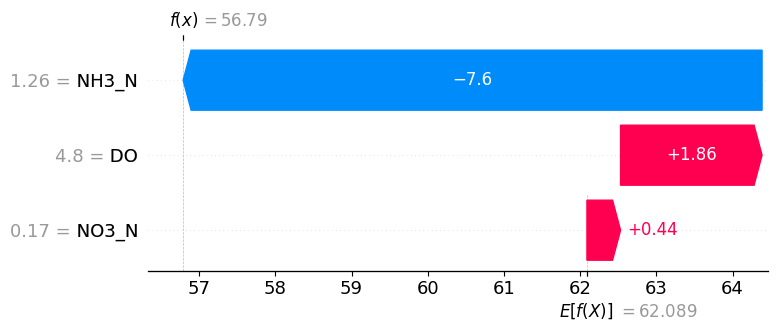

In [ ]:
shap.plots.waterfall(shap_values[0])

In [ ]:
display(scenario_results.round(4))

,Scenario,Features,R2,MAE,RMSE
0,Full Parameters,6,0.8422,3.1332,4.1259
1,Reduced Parameters,3,0.6854,4.2617,5.8264


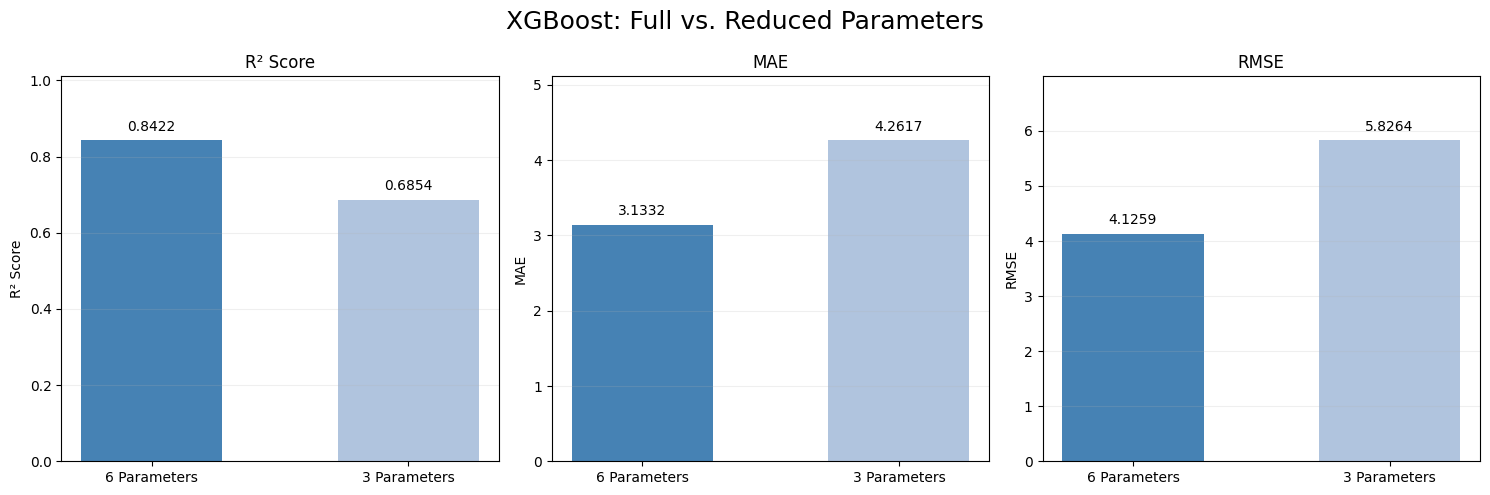

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

metrics = ["R2", "MAE", "RMSE"]
titles = ["R² Score", "MAE", "RMSE"]

for i, metric in enumerate(metrics):

    bars = axes[i].bar(
        ["6 Parameters", "3 Parameters"],
        scenario_results[metric],
        color=["steelblue", "lightsteelblue"],
        width=0.55
    )

    axes[i].bar_label(bars, fmt="%.4f", padding=5)
    axes[i].set_title(titles[i])
    axes[i].set_ylabel(titles[i])
    axes[i].set_ylim(0, scenario_results[metric].max() * 1.2)
    axes[i].grid(axis="y", alpha=0.2)

plt.suptitle(
    "XGBoost: Full vs. Reduced Parameters",
    fontsize=18
)

plt.tight_layout()
plt.savefig("Full_vs_Reduced_Parameters.png", dpi=300,
            bbox_inches="tight")

plt.show()

In [ ]:
full = scenario_results.iloc[0]
reduced = scenario_results.iloc[1]

feature_reduction = (
    (full["Features"] - reduced["Features"])
    / full["Features"]
) * 100

r2_decrease = full["R2"] - reduced["R2"]

mae_increase = reduced["MAE"] - full["MAE"]

rmse_increase = reduced["RMSE"] - full["RMSE"]

print(f"Feature Reduction: {feature_reduction:.2f}%")
print(f"R2 Decrease: {r2_decrease:.4f}")
print(f"MAE Increase: {mae_increase:.4f}")
print(f"RMSE Increase: {rmse_increase:.4f}")

Feature Reduction: 50.00%
R2 Decrease: 0.1568
MAE Increase: 1.1285
RMSE Increase: 1.7004
